<a href="https://colab.research.google.com/github/owlmt/QML/blob/main/23_Adversarial_Attacks_Against_QML/QNN_AdversarialRobustness_Wendlinger2024.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Quantum vs classical adversarial robustness: re-upload / amplitude-encoding circuits, a Fourier network and a ConvNet (Wendlinger et al., 2024) step by step

This notebook re-implements, runs and checks the experiments of

> Maximilian Wendlinger, Kilian Tscharke and Pascal Debus,
> "A Comparative Analysis of Adversarial Robustness for Quantum and Classical Machine Learning Models",
> Fraunhofer AISEC / TU Munich, 2024 (arXiv preprint). https://arxiv.org/abs/2404.16154

The paper's dataset, code and weights were "to be released upon publication" and are not public, so everything below is written from
the paper's text and appendices, with the stack the paper names (PennyLane circuits, PyTorch training).

**What the notebook does.** It builds the paper's four-class synthetic image dataset (16 x 16 pictures of the symbols `-`, `+`, `|-`, `-|`
with +-10 degree rotation, blur and varying bar thickness), trains the paper's four model families (an 8-qubit *re-upload encoding*
variational circuit with 32 `StronglyEntanglingLayers` and 1536 parameters, an 8-qubit *amplitude-encoding* circuit, a one-layer
*ConvNet*, and the classical *Fourier network* that approximates the re-upload circuit), adds the paper's Lipschitz-regularised
variants ReUp(0.1) and ReUp(0.2), attacks all of them with white-box **PGD** at several strengths, and then repeats every experiment
of the paper that can be repeated: accuracy under attack (Fig. 2), the perturbation images (Fig. 3, 7), the full source-to-target
**transfer-attack matrix** (Fig. 4), transfers into and out of the regularised quantum models (Fig. 5, 6) and the **Lipschitz bounds** of
Table I. Classical scikit-learn baselines (random forest, RBF-SVM) are trained on the same pixels and attacked by transfer. The last
section lists every checkable claim next to the number this notebook obtained.

**How to run it.** Open in Colab (badge above), choose a CPU runtime, and use *Runtime -> Run all*. The first cell installs a pinned
PennyLane (used to verify our simulator); if Colab asks to restart the session, restart and run all again. No GPU, no quantum account.

**Runtime.** `FAST_MODE = True` (600 training images, 8 / 20 epochs, 5 PGD steps, one seed) takes about 6 minutes on a laptop CPU.
`FAST_MODE = False` follows the paper's budgets (1000 training images, 20 and 100 epochs, 20 PGD steps, 5 seeds for the classical
models, 3 seeds for three of the quantum models) and took 70 minutes on an 8-core laptop CPU that was shared with other jobs
(the four 100-epoch quantum trainings alone took about 60 of those minutes; expect less on an idle machine, more on a 2-core Colab CPU).

**What you get at the end.** Re-drawn Figures 1-7, Table I recomputed, a seed-variation table, and a claim-by-claim comparison with a
verdict ("reproduced" / "not reached" / "exceeded") for each statement of the paper, followed by a critical reading and exercises.


## The paper in one page

**Problem.** Are quantum classifiers more adversarially robust than classical ones? An earlier study (West et al., 2023) saw that
attacks crafted on classical networks failed to fool amplitude-encoded quantum circuits and suspected a "quantum advantage in robustness
by design". This paper asks whether that survives a careful comparison of architectures, training time and regularisation.

**Decision.** Four-class image classification of 16 x 16 grey-scale pictures of the symbols `-`, `+`, `|-`, `-|` (class 0..3). The
dataset is designed so that the pixels an attack *should* change to turn one class into another are known (e.g. adding a vertical bar
to a `-` makes a `+`), which lets one judge whether an attack perturbs meaningful features or random noise.

**Models** (cross-entropy on the softmax of four outputs; PennyLane circuits through `TorchLayer`, classical nets in PyTorch):

| Model | Definition | Parameters |
|---|---|---|
| ReUp(lambda) | 8 qubits, 32 `StronglyEntanglingLayers`; every rotation angle is `w * x + theta` (trainable encoding weight times an image pixel, plus bias); the 256 pixels are used three times; read-out `<Z>` of the first four qubits | 1536 |
| AmpEnc | `AmplitudeEmbedding` of the normalised 256 pixels on 8 qubits, then 32 `StronglyEntanglingLayers` with only biases | 768 |
| ConvNet | one 5 x 5 convolution (6 channels), ReLU, max-pool, one linear layer to 4 outputs | 1024 |
| Fourier net | single hidden layer of 64 units alternating sine and cosine of 32 shared linear projections, linear read-out; a classical surrogate of the re-upload circuit's Fourier series | - |

**Training.** Adam, learning rate 0.001, batch size 50, no weight decay, 1000 training / 200 test images, 20 epochs (some experiments
100); barren-plateau-free small initialisation; averages over 5 seeds for the training curves. ReUp(lambda) adds the Lipschitz regulariser of
Berberich et al. (2023), `lambda * sum_j ||w_j||^2 ||H_j||^2`, with lambda in {0.0, 0.1, 0.2}.

**Attack.** L-infinity PGD (Madry et al.), eps in {0.05, 0.1, 0.2}, on 100 test images; "transfer attack" = apply the perturbed images of a
source model to another (target) model.

**Theory.** Lipschitz bound of a ReUp model `L = 2 ||M|| sum_j ||w_j|| ||H_j||` (Berberich et al.); for classical models LipSDP (Fazlyab et al.)
for the Fourier net and the spectral norm of the Toeplitz-matrix form of the convolution for the ConvNet.

**Claims checked here.**

| Claim | Paper |
|---|---|
| Model sizes | ConvNet 1024 parameters, ReUp 1536 |
| Training | validation accuracy >= 99 % after 10 epochs for all models (Fig. 11) |
| Fig. 2 | all models "drastically" lose accuracy for small eps; the 100-epoch ReUp is less robust than the 20-epoch ReUp |
| Fig. 4 | transfers work between ConvNet, Fourier and ReUp (Fourier -> ReUp degrades ReUp "by 0.5", more than the reverse); AmpEnc is robust to incoming transfer attacks and its own attacks do not transfer out |
| Fig. 5, 6 | regularisation protects ReUp against Fourier-net attacks; attacks from more strongly regularised ReUp transfer better to the Fourier net; attacks from 100-epoch models transfer worse |
| Fig. 3, 7 | AmpEnc perturbations are most scattered; long training and no regularisation give noisier ReUp patterns |
| Table I | Lipschitz bounds 73.11 / 106.33 (ReUp(0.0), 20 / 100 ep), 18.18 / 19.77 (0.1), 13.50 / 11.83 (0.2), Fourier 25.38, ConvNet 20.24 |


### What follows the paper and what had to be chosen

The paper gives architectures and the training recipe but not the dataset generator, the PGD iteration count, the exact weight
initialisation, how the Lipschitz regulariser is scaled, or the numeric values behind its figures (they are bar charts and heat maps
without printed values, only Table I and a few sentences give numbers). Everything unspecified is marked `# CHOICE:` in the code.

| Item | Paper | This notebook |
|---|---|---|
| Dataset | 4 classes, 16 x 16, rotations +-10 deg, blur, varying thickness; 1000 train / 200 test; **not public** | own generator following that description (bar drawings, thickness 1-2 px, +-1 px bar position, Gaussian blur sigma 0.3-0.8); 1000 / 200 |
| Model sizes and training | 8 qubits, L = 32, Adam 0.001, batch 50, 20 and 100 epochs | same (FAST_MODE: 600 images, 8 / 20 epochs, Adam 0.003) |
| Quantum simulation | PennyLane `TorchLayer` | an equivalent hand-written batched PyTorch state-vector simulator (12 x faster than PennyLane + torch, verified against `qml.StronglyEntanglingLayers` / `qml.AmplitudeEmbedding` to 1e-6 in outputs and input gradients) |
| Re-upload input layout | "each feature is shown three times", 768 angles | the 256 pixels are tiled three times over the `32 x 8 x 3` angle tensor |
| Initialisation | "small values" | normal, std 0.01 for encoding weights and biases (ReUp, AmpEnc); PyTorch defaults for the classical nets |
| Regulariser | `lambda * sum_j ||w_j||^2 ||H_j||^2` | `lambda * 0.25 * sum w^2` (every Rot generator has `||H_j|| = 1/2`), added to the batch-mean cross-entropy |
| Attack | PGD, eps in {0.05, 0.1, 0.2}, 100 images, white box | L-infinity PGD, 20 steps, alpha = 2.5 eps / steps, no random start, no clipping to [0,1] (the paper plots delta in [-eps, eps]); first 100 test images |
| Seeds | 5 initialisation seeds for the training curves; attack results from one run | main seed 42; extra seeds for the Table-I/PGD summary (5 classical, 3 for AmpEnc, ReUp(0.0), ReUp(0.2)) |
| Lipschitz bounds | LipSDP (Fazlyab et al.) for the Fourier net, Toeplitz spectral norm for ConvNet, Berberich bound for ReUp | exact Berberich formula for ReUp; *spectral-norm product* for the Fourier net (no SDP solver needed; LipSDP is a tighter refinement); Toeplitz spectral norm for ConvNet; plus an empirical local Jacobian lower bound for every model |
| Semantic-alignment score | perturbation patterns judged by eye | our own number: cosine similarity between `delta` and the difference of the true and the predicted class mean image (0 = unrelated to the label change, 1 = exactly the change a human would draw) |
| Black-box baselines | none | random forest and RBF-SVM on the 256 pixels, attacked by transfer |


## 0. Setup

In [1]:
# Versions tested with this notebook (October 2026). Colab already ships numpy, pandas, scikit-learn, scipy,
# matplotlib and PyTorch; only PennyLane (used to verify our fast simulator) is added.
# The pip line runs on Colab (or wherever PennyLane is missing); a prepared local environment is left untouched.
import importlib.util
IN_COLAB = importlib.util.find_spec("google.colab") is not None
if IN_COLAB or importlib.util.find_spec("pennylane") is None:
    %pip install -q "pennylane==0.45.1"
    print("Packages installed. If Colab asks you to restart the session, do so and run all cells again.")
else:
    print("pennylane already present; skipping pip install.")


pennylane already present; skipping pip install.


In [2]:
# ---------------- configuration ----------------
FAST_MODE = False        # True: class demo (about 6 minutes on a laptop CPU). False: the paper's budgets (about 1.5 hours on a shared CPU).

SEED       = 42          # CHOICE: the paper gives no seed (it averages 5 initialisation seeds for the training curves)
N_QUBITS   = 8           # paper: 8 qubits (a 16 x 16 image has 256 = 2^8 amplitudes)
N_LAYERS   = 32          # paper: L = 32 StronglyEntanglingLayers (fixed: the 256 pixels are tiled 3x over 32 x 8 x 3 gate angles)
IMG        = 16          # paper: 16 x 16 grey-scale images, pixels in [0, 1]
N_TRAIN    = 600 if FAST_MODE else 1000   # paper: 1000 training images (FAST_MODE trains on fewer to save time)
N_TEST     = 200         # paper: 200 test ("validation") images

E_SHORT    = 8 if FAST_MODE else 20       # paper: models are attacked after 20 epochs ...
E_LONG     = 20 if FAST_MODE else 100     # ... and, for the training-time experiments, after 100 epochs
LR         = 3e-3 if FAST_MODE else 1e-3  # paper: Adam, learning rate 0.001 (FAST_MODE uses a larger step to converge in fewer epochs)
BATCH      = 50          # paper: batch size 50
LAMBDAS    = [0.0, 0.1, 0.2]              # paper: Lipschitz-regularisation strengths of the ReUp(lambda) models
INIT_SCALE = 0.01        # CHOICE: paper says "small values" for encoding weights and biases (barren-plateau-free start)

EPS_MAIN   = 0.1         # paper: PGD(0.1) is the attack used for the transfer experiments
EPS_LIST   = [0.05, 0.1, 0.2]                       # paper: attack strengths of Fig. 2
EPS_CURVE  = [0.0, 0.025, 0.05, 0.1, 0.15, 0.2]     # CHOICE: a denser grid for the accuracy-vs-epsilon curve
N_ATTACK   = 60 if FAST_MODE else 100               # paper: 100 images are attacked
PGD_STEPS  = 5 if FAST_MODE else 20                 # CHOICE: the paper does not give the number of PGD iterations
PGD_ALPHA_FACTOR = 2.5   # CHOICE: step size alpha = 2.5 * eps / steps (Madry et al.'s rule of thumb); no random start

N_CLASSICAL_SEEDS = 2 if FAST_MODE else 5   # CHOICE: extra seeds for the cheap classical models (paper averages 5 seeds for training curves)
N_Q_EXTRA_SEEDS   = 0 if FAST_MODE else 2   # CHOICE: extra seeds (20-epoch models only) for the slow quantum models

DATA_DIR   = "data"      # the dataset is generated, not downloaded; a cached copy is written here
IBM_TOKEN  = ""          # unused: every circuit is simulated exactly, no quantum hardware is needed


In [3]:
import os, time, math, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from scipy.ndimage import rotate, gaussian_filter

warnings.filterwarnings("ignore", category=DeprecationWarning)
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)

import torch, torch.nn as nn, torch.nn.functional as F
import pennylane as qml
import sklearn
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

torch.manual_seed(SEED); np.random.seed(SEED)       # seeds everywhere: torch, numpy, scikit-learn (random_state=SEED below)
rng_data = np.random.default_rng(SEED)              # a dedicated generator for the synthetic dataset
os.makedirs(DATA_DIR, exist_ok=True)
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 40)
plt.rcParams.update({"figure.dpi": 90, "axes.grid": False})

print("torch", torch.__version__, "| pennylane", qml.version(), "| numpy", np.__version__, "| scikit-learn", sklearn.__version__)
print("FAST_MODE =", FAST_MODE, "| epochs", E_SHORT, "/", E_LONG, "| train", N_TRAIN, "| PGD steps", PGD_STEPS, "| attacked images", N_ATTACK)


torch 2.14.1+cpu | pennylane 0.45.1 | numpy 2.5.4 | scikit-learn 1.9.1
FAST_MODE = False | epochs 20 / 100 | train 1000 | PGD steps 20 | attacked images 100


## 1. The dataset: four bar symbols, 16 x 16 pixels

The paper builds a toy dataset on purpose. Class 0 is a horizontal bar `-`, class 1 a plus `+`, class 2 a vertical bar with an arm to the right
`|-`, class 3 a vertical bar with an arm to the left `-|`. Each image is rotated by a random angle in +-10 degrees, blurred, and drawn with a
random bar thickness; pixel values lie in [0, 1] as in MNIST. 1000 balanced, randomly permuted training images and 200 test images
(which the paper also calls the *validation* set; we never tune anything on it, so there is no leakage).

The point of the construction: to turn a `-` into a `+` an attacker must add a *vertical bar*; to turn `|-` into `+` it must add a *left half-bar*.
These semantically meaningful changes are known in advance, so one can tell whether an attack alters the right pixels or just adds noise
(Fig. 3 and 7). The generator is ours (the paper's was not released), so the exact pixels differ but the task is the same.


using cached data\synthetic_bars_1000_200_seed42.npz
train (1000, 16, 16), test (200, 16, 16); class counts train [250, 250, 250, 250], test [50, 50, 50, 50]
pixel range [0.00, 1.00]  (paper: values in [0, 1])


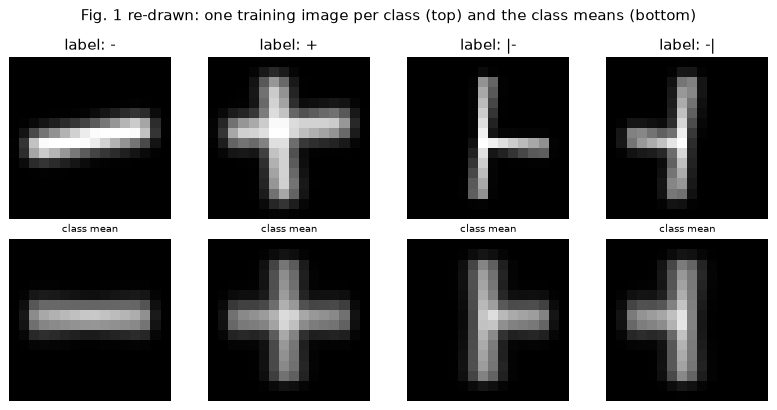

In [4]:
CLASS_NAMES = ["-", "+", "|-", "-|"]   # class 0 .. 3  (the paper's  -  +  |-  -| )

def make_image(k, rng):
    """One 16 x 16 image of class k: a bar drawing, random +-10 degree rotation, blur, random bar thickness (paper, Sec. IV-A)."""
    img = np.zeros((IMG, IMG))
    t = int(rng.integers(1, 3))                          # CHOICE: bar thickness 1 or 2 pixels (paper: "different thicknesses")
    r0 = max(7 + int(rng.integers(0, 2)) - (t - 1), 0)   # CHOICE: row of the horizontal bar (centre +- 1 pixel)
    c0 = max(7 + int(rng.integers(0, 2)) - (t - 1), 0)   # CHOICE: column of the vertical bar
    if k == 0:                                           # '-'  horizontal bar
        img[r0:r0 + t, 2:14] = 1
    elif k == 1:                                         # '+'  both bars
        img[r0:r0 + t, 2:14] = 1; img[2:14, c0:c0 + t] = 1
    elif k == 2:                                         # '|-' vertical bar with an arm to the right
        img[2:14, c0:c0 + t] = 1; img[r0:r0 + t, c0:14] = 1
    else:                                                # '-|' vertical bar with an arm to the left
        img[2:14, c0:c0 + t] = 1; img[r0:r0 + t, 2:c0 + t] = 1
    img = rotate(img, rng.uniform(-10, 10), reshape=False, order=1, mode="constant")   # paper: random rotations of +-10 degrees
    img = gaussian_filter(img, rng.uniform(0.3, 0.8))                                    # paper: blurs; CHOICE of sigma range
    return np.clip(img / max(img.max(), 1e-6), 0, 1)

def make_dataset(n, rng):
    y = np.repeat(np.arange(4), n // 4)                  # paper: balanced in the classes ...
    X = np.stack([make_image(k, rng) for k in y])
    p = rng.permutation(len(y))                          # ... and randomly permuted
    return X[p].astype(np.float32), y[p]

cache = os.path.join(DATA_DIR, f"synthetic_bars_{N_TRAIN}_{N_TEST}_seed{SEED}.npz")
if os.path.exists(cache):
    d = np.load(cache); Xtr_np, ytr_np, Xte_np, yte_np = d["Xtr"], d["ytr"], d["Xte"], d["yte"]; print("using cached", cache)
else:
    Xtr_np, ytr_np = make_dataset(N_TRAIN, rng_data); Xte_np, yte_np = make_dataset(N_TEST, rng_data)
    np.savez_compressed(cache, Xtr=Xtr_np, ytr=ytr_np, Xte=Xte_np, yte=yte_np)
Xtr, ytr, Xte, yte = map(torch.as_tensor, (Xtr_np, ytr_np.astype(np.int64), Xte_np, yte_np.astype(np.int64)))
print(f"train {tuple(Xtr.shape)}, test {tuple(Xte.shape)}; class counts train {np.bincount(ytr_np).tolist()}, test {np.bincount(yte_np).tolist()}")
print(f"pixel range [{Xtr.min():.2f}, {Xtr.max():.2f}]  (paper: values in [0, 1])")

# class-mean images: used below to find out which pixels a *semantically meaningful* attack has to change
CLASS_MEAN = np.stack([Xtr_np[ytr_np == k].mean(0) for k in range(4)])

fig, ax = plt.subplots(2, 4, figsize=(9, 4.6))
for k in range(4):
    ax[0, k].imshow(Xtr_np[np.flatnonzero(ytr_np == k)[0]], cmap="gray", vmin=0, vmax=1)
    ax[0, k].set_title(f"label: {CLASS_NAMES[k]}"); ax[0, k].axis("off")
    ax[1, k].imshow(CLASS_MEAN[k], cmap="gray", vmin=0, vmax=1)
    ax[1, k].set_title("class mean", fontsize=8); ax[1, k].axis("off")
plt.suptitle("Fig. 1 re-drawn: one training image per class (top) and the class means (bottom)"); plt.tight_layout(); plt.show()


## 2. The four model families

**Re-upload encoding circuit (ReUp).** A 16 x 16 image is a vector of 256 numbers. The model has 8 qubits and 32 `StronglyEntanglingLayers`;
each layer is one general rotation `Rot(phi, theta, omega)` per qubit followed by a ring of CNOTs. In the *re-upload* design the rotation
angles contain the data: angle = `w * pixel + theta`, where `w` (encoding weight) and `theta` (bias) are trained. 32 layers x 8 qubits x 3
angles = 768 angle slots, so the 256 pixels are fed in three times, and there are 768 + 768 = 1536 trainable numbers. The class scores are
the expectation values of Pauli-Z on the first four qubits (class k = qubit k).

**Amplitude-encoding circuit (AmpEnc).** The normalised 256 pixels are loaded directly as the amplitudes of the 8-qubit state; the 32
layers then contain only trainable biases (768 numbers), no data. This is the architecture used by West et al. and cannot easily be run on
hardware, because loading 256 amplitudes is deep.

**ConvNet.** The simplest convolutional classifier that still solves the task: one 5 x 5 convolution with 6 channels, ReLU, 2 x 2 max-pool, one
linear layer to four outputs: 156 + 868 = 1024 parameters.

**Fourier network.** A re-upload circuit computes a truncated Fourier series in the input, `f(x) = sum_w a_w cos(w x) + b_w sin(w x)`
(Schuld et al. 2021). The Fourier net is its classical surrogate: one hidden layer whose units are alternately `sin(u)` and `cos(u)` of
32 shared linear projections `u = W0 x + b0`, followed by a linear layer. It sits "in the middle" between circuits and ordinary networks.

**Simulation.** The paper uses PennyLane circuits wrapped in `TorchLayer`; on a CPU one training step of a 32-layer, 8-qubit model then
needs about 3 s, which would make a 100-epoch run (2000 steps) take about 100 minutes per model. We therefore simulate the same circuits
with a small batched PyTorch state-vector code (rotations of four wires are merged into one 16 x 16 matrix per layer) and *verify it against
PennyLane's own `StronglyEntanglingLayers` and `AmplitudeEmbedding`*, for outputs and for the gradient with respect to the input (which is what PGD uses).


In [5]:
# ----------------------------------------------------------------------------------------------------------------
# A fast batched state-vector simulator for the paper's circuits, written in plain PyTorch.
# Why: PennyLane's TorchLayer needs about 3 s per batch-of-50 forward+backward pass for 8 qubits x 32 layers on a CPU
# (2000 steps for one 100-epoch model = 100 minutes); this simulator needs about 0.25 s. It is verified against PennyLane
# (qml.StronglyEntanglingLayers, qml.AmplitudeEmbedding) in the next cell, outputs and input-gradients agree to ~1e-6.
# ----------------------------------------------------------------------------------------------------------------
Q, L = N_QUBITS, N_LAYERS
CDT = torch.complex64

def layer_src(l):
    """Index map of the ring of CNOTs of StronglyEntanglingLayers layer l: CNOT(i, (i + r) % Q), r = l % (Q-1) + 1."""
    r = (l % (Q - 1)) + 1
    idx = np.arange(2 ** Q); cur = idx.copy()
    for i in range(Q):
        t = (i + r) % Q
        cbit = (idx >> (Q - 1 - i)) & 1                  # wire 0 is the most significant bit (PennyLane convention)
        cur = cur[idx ^ (cbit << (Q - 1 - t))]
    return torch.as_tensor(cur, dtype=torch.long)

SRC   = [layer_src(l) for l in range(L)]
ZSIGN = torch.stack([1 - 2 * ((torch.arange(2 ** Q) >> (Q - 1 - q)) & 1).float() for q in range(4)], 0)   # <Z_q> signs, q = 0..3

def rot_mats(a):
    """Matrices of qml.Rot(phi, theta, omega) = RZ(omega) RY(theta) RZ(phi) for angles a[..., 3] -> [..., 2, 2]."""
    phi, th, om = a[..., 0], a[..., 1], a[..., 2]
    c, s = torch.cos(th / 2), torch.sin(th / 2)
    e = lambda z: torch.polar(torch.ones_like(z), z)     # exp(i z)
    m00 = e(-(phi + om) / 2) * c; m01 = -e((phi - om) / 2) * s
    m10 = e(-(phi - om) / 2) * s; m11 = e((phi + om) / 2) * c
    return torch.stack([torch.stack([m00, m01], -1), torch.stack([m10, m11], -1)], -2)

def kron_n(M):
    """Kronecker product of the 2x2 matrices M[..., j, :, :] over j."""
    out = M[..., 0, :, :]
    for j in range(1, M.shape[-3]):
        n = out.shape[-1]
        out = torch.einsum("...ij,...kl->...ikjl", out, M[..., j, :, :]).reshape(*out.shape[:-2], 2 * n, 2 * n)
    return out

def run_sel(state, ang):
    """Apply L StronglyEntanglingLayers with per-sample angles ang[B, L, Q, 3] to a batch of states [B, 2^Q]."""
    B = state.shape[0]
    if ang.dim() == 3:
        ang = ang.unsqueeze(0).expand(B, -1, -1, -1)
    U = rot_mats(ang)                                    # [B, L, Q, 2, 2]
    UA = kron_n(U[:, :, :4]).unbind(1)                   # rotations of wires 0-3 as one 16 x 16 matrix per layer
    UB = kron_n(U[:, :, 4:]).transpose(-1, -2).unbind(1) # rotations of wires 4-7
    s = state.reshape(B, 16, 16)
    for l in range(L):
        s = UA[l] @ s @ UB[l]
        s = s.reshape(B, 2 ** Q)[:, SRC[l]].reshape(B, 16, 16)
    return s.reshape(B, 2 ** Q)

def expz(state):
    """<Z_0>, ..., <Z_3>: the four class scores (paper: measure the first four qubits)."""
    return (state.real ** 2 + state.imag ** 2) @ ZSIGN.T


class ReUp(nn.Module):
    """Re-upload encoding classifier (paper, Fig. 8): angle of every Rot gate = w * x_tiled + theta, 1536 parameters."""
    def __init__(self):
        super().__init__()
        self.w     = nn.Parameter(INIT_SCALE * torch.randn(L, Q, 3))   # trainable encoding weights (768)
        self.theta = nn.Parameter(INIT_SCALE * torch.randn(L, Q, 3))   # trainable biases (768)
    def forward(self, x):
        B = x.shape[0]; x = x.reshape(B, -1)
        # CHOICE: the 256 pixels are repeated three times to fill the 32 x 8 x 3 = 768 gate angles ("three times re-upload encoding")
        ang = self.w * x.repeat(1, 3).reshape(B, L, Q, 3) + self.theta
        st = torch.zeros(B, 2 ** Q, dtype=CDT); st[:, 0] = 1
        return expz(run_sel(st, ang))
    def reg(self):
        """lambda-term of Eq. (8): sum_j ||w_j||^2 ||H_j||^2 with ||H_j|| = 1/2 for the generators sigma/2 of qml.Rot."""
        return 0.25 * (self.w ** 2).sum()

class AmpEnc(nn.Module):
    """Amplitude-encoding classifier (paper, Fig. 9): AmplitudeEmbedding of the normalised image, then L layers; 768 parameters."""
    def __init__(self):
        super().__init__()
        self.theta = nn.Parameter(INIT_SCALE * torch.randn(L, Q, 3))
    def forward(self, x):
        B = x.shape[0]; x = x.reshape(B, -1)
        st = (x / x.norm(dim=1, keepdim=True)).to(CDT)
        return expz(run_sel(st, self.theta))
    def reg(self):
        return torch.zeros(())

class ConvNet(nn.Module):
    """Paper App. A.B: one 5x5 convolution with 6 channels, ReLU, 2x2 max-pool, one linear layer to 4 outputs (1024 parameters)."""
    def __init__(self):
        super().__init__()
        self.conv = nn.Conv2d(1, 6, 5); self.fc = nn.Linear(6 * 6 * 6, 4)
    def forward(self, x):
        x = x.reshape(-1, 1, IMG, IMG)
        return self.fc(F.max_pool2d(F.relu(self.conv(x)), 2).flatten(1))
    def reg(self):
        return torch.zeros(())

class FourierNet(nn.Module):
    """Paper App. A.B / Fig. 10: 64 hidden units alternately sin / cos of 32 shared pre-activations, then a linear layer to 4 logits."""
    def __init__(self, hidden=32):
        super().__init__()
        self.enc = nn.Linear(IMG * IMG, hidden); self.out = nn.Linear(2 * hidden, 4)
    def forward(self, x):
        u = self.enc(x.reshape(x.shape[0], -1))
        return self.out(torch.cat([torch.sin(u), torch.cos(u)], 1))   # sin and cos units share the encoding weights
    def reg(self):
        return torch.zeros(())

def n_params(m):
    return sum(p.numel() for p in m.parameters())


In [6]:
# ---- verify the fast simulator against PennyLane's own templates (double precision) ----
dev = qml.device("default.qubit", wires=Q)

@qml.qnode(dev, interface="torch", diff_method="backprop")
def pl_reup(x_tiled, w, theta):
    qml.StronglyEntanglingLayers(w * x_tiled.reshape(-1, L, Q, 3) + theta, wires=range(Q))
    return [qml.expval(qml.PauliZ(i)) for i in range(4)]

@qml.qnode(dev, interface="torch", diff_method="backprop")
def pl_amp(x, theta):
    qml.AmplitudeEmbedding(x, wires=range(Q), normalize=True)
    qml.StronglyEntanglingLayers(theta, wires=range(Q))
    return [qml.expval(qml.PauliZ(i)) for i in range(4)]

g = torch.Generator().manual_seed(SEED)
w_t, th_t = 0.3 * torch.randn(L, Q, 3, generator=g), 0.3 * torch.randn(L, Q, 3, generator=g)
x_t = torch.rand(3, IMG * IMG, generator=g)

m = ReUp(); m.w.data, m.theta.data = w_t.clone(), th_t.clone()
x1 = x_t.clone().requires_grad_(True); ours = m(x1); ours[:, 1].sum().backward()
x2 = x_t.repeat(1, 3).double().requires_grad_(True)
ref = torch.stack(pl_reup(x2, w_t.double(), th_t.double()), -1); ref[:, 1].sum().backward()
print(f"ReUp   : max |output difference| = {(ours - ref).abs().max().item():.1e}, "
      f"max |dx difference| = {(x1.grad - x2.grad.reshape(3, 3, -1).sum(1)).abs().max().item():.1e}   (PennyLane vs ours)")

a = AmpEnc(); a.theta.data = th_t.clone()
x1 = x_t.clone().requires_grad_(True); ours = a(x1); ours[:, 1].sum().backward()
x2 = x_t.double().requires_grad_(True)
ref = torch.stack(pl_amp(x2, th_t.double()), -1); ref[:, 1].sum().backward()
print(f"AmpEnc : max |output difference| = {(ours - ref).abs().max().item():.1e}, max |dx difference| = {(x1.grad - x2.grad).abs().max().item():.1e}")
assert (ours - ref).abs().max() < 1e-4, "simulator disagrees with PennyLane"

print("\ntrainable parameters:")
for nm, mod, paper in [("ReUp", ReUp(), "1536 (768 weights + 768 biases)"), ("AmpEnc", AmpEnc(), "768"),
                       ("ConvNet", ConvNet(), "1024"), ("FourierNet", FourierNet(), "not stated")]:
    print(f"  {nm:10s} ours {n_params(mod):6d}   paper: {paper}")
t0 = time.time(); mm = ReUp(); xb = Xtr[:BATCH].clone().requires_grad_(True); mm(xb).sum().backward()
print(f"one forward+backward pass of the 8-qubit, 32-layer ReUp model on {BATCH} images: {time.time() - t0:.2f} s")


ReUp   : max |output difference| = 1.9e-07, max |dx difference| = 1.8e-07   (PennyLane vs ours)


AmpEnc : max |output difference| = 1.9e-07, max |dx difference| = 6.4e-08

trainable parameters:
  ReUp       ours   1536   paper: 1536 (768 weights + 768 biases)
  AmpEnc     ours    768   paper: 768
  ConvNet    ours   1024   paper: 1024
  FourierNet ours   8484   paper: not stated


one forward+backward pass of the 8-qubit, 32-layer ReUp model on 50 images: 0.21 s


## 3. Training and the classical baselines

All models use Adam (learning rate 0.001, batch size 50, no weight decay) with cross-entropy on the softmax of the four outputs. The
re-upload models with `lambda > 0` add the Lipschitz regulariser of Berberich et al., which penalises the size of the encoding weights.
The quantum models are trained for 100 epochs and **frozen copies are kept after 20 and after 100 epochs**, so every experiment can be
run at both training times (the paper attacks "the 20-epoch model" and "the 100-epoch model"). The small initialisation (std 0.01)
makes the whole circuit start close to the identity, which avoids barren plateaus.

Two plain scikit-learn models (random forest, RBF-SVM) are trained on the same 256 pixels as baselines. They have no gradient that
our attack could use here, so they only appear later as *black-box targets* of transfer attacks.


ConvNet    trained  20 epochs in   12.4 s | val acc at epoch 10: 1.000 | at epoch 20: 1.000


Fourier    trained  20 epochs in    1.6 s | val acc at epoch 10: 1.000 | at epoch 20: 1.000


AmpEnc     trained 100 epochs in  599.3 s | val acc at epoch 10: 0.945 | at epoch 20: 0.970 | at epoch 100: 0.960


ReUp(0.0)  trained 100 epochs in 1166.9 s | val acc at epoch 10: 0.990 | at epoch 20: 0.975 | at epoch 100: 0.995


ReUp(0.1)  trained 100 epochs in  730.9 s | val acc at epoch 10: 0.930 | at epoch 20: 0.970 | at epoch 100: 0.805


ReUp(0.2)  trained 100 epochs in  363.3 s | val acc at epoch 10: 0.780 | at epoch 20: 0.950 | at epoch 100: 0.800


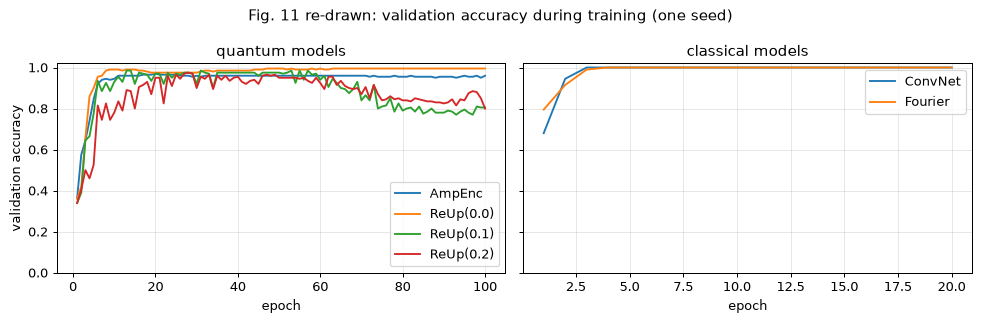

In [7]:
SPECS = [("ConvNet", ConvNet, 0.0), ("Fourier", FourierNet, 0.0), ("AmpEnc", AmpEnc, 0.0),
         ("ReUp(0.0)", ReUp, 0.0), ("ReUp(0.1)", ReUp, 0.1), ("ReUp(0.2)", ReUp, 0.2)]
QUANTUM = ["AmpEnc", "ReUp(0.0)", "ReUp(0.1)", "ReUp(0.2)"]
CLASSICAL = ["ConvNet", "Fourier"]
FACTORY = {n: (f, lam) for n, f, lam in SPECS}

def train_model(name, seed, epochs, snaps):
    """Adam (lr LR, batch BATCH, no weight decay); loss = cross-entropy of softmax(model output) + lambda * Lipschitz regulariser.
    Returns the per-epoch validation accuracy and frozen copies of the model after the epochs listed in `snaps`."""
    torch.manual_seed(seed)
    factory, lam = FACTORY[name]
    model = factory()
    opt = torch.optim.Adam(model.parameters(), lr=LR)
    gen = torch.Generator().manual_seed(seed)
    hist, frozen = [], {}
    for ep in range(1, epochs + 1):
        perm = torch.randperm(len(ytr), generator=gen)
        for i in range(0, len(ytr), BATCH):
            b = perm[i:i + BATCH]
            loss = F.cross_entropy(model(Xtr[b]), ytr[b]) + lam * model.reg()
            opt.zero_grad(); loss.backward(); opt.step()
        with torch.no_grad():
            hist.append((model(Xte).argmax(1) == yte).float().mean().item())
        if ep in snaps:
            import copy
            frozen[ep] = copy.deepcopy(model).eval()
    return hist, frozen

MODELS, HIST, TRAIN_TIME = {}, {}, {}      # MODELS[(name, epoch)] = frozen model; HIST[name] = validation accuracy per epoch
for name, _, lam in SPECS:
    quantum = name in QUANTUM
    epochs = E_LONG if quantum else E_SHORT        # classical models are only needed at the short horizon
    t0 = time.time()
    HIST[name], frozen = train_model(name, SEED, epochs, snaps={E_SHORT, E_LONG} if quantum else {E_SHORT})
    TRAIN_TIME[name] = time.time() - t0
    for ep, mod in frozen.items():
        MODELS[(name, ep)] = mod
    print(f"{name:10s} trained {epochs:3d} epochs in {TRAIN_TIME[name]:6.1f} s | val acc at epoch {min(10, epochs)}: {HIST[name][min(10, epochs) - 1]:.3f}"
          f" | at epoch {E_SHORT}: {HIST[name][E_SHORT - 1]:.3f}" + (f" | at epoch {E_LONG}: {HIST[name][-1]:.3f}" if quantum else ""), flush=True)

fig, ax = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
for name in QUANTUM:
    ax[0].plot(range(1, len(HIST[name]) + 1), HIST[name], label=name)
for name in CLASSICAL:
    ax[1].plot(range(1, len(HIST[name]) + 1), HIST[name], label=name)
for a_, t_ in zip(ax, ["quantum models", "classical models"]):
    a_.set_title(t_); a_.set_xlabel("epoch"); a_.legend(); a_.grid(alpha=0.3)
ax[0].set_ylabel("validation accuracy"); ax[0].set_ylim(0, 1.02)
plt.suptitle("Fig. 11 re-drawn: validation accuracy during training (one seed)"); plt.tight_layout(); plt.show()


,model,epochs,clean test acc,"train time (s, whole run)"
0,ConvNet,20,1.000,12.424
1,Fourier,20,1.000,1.550
2,AmpEnc,20,0.970,599.324
3,AmpEnc,100,0.960,599.324
4,ReUp(0.0),20,0.975,1166.869
5,ReUp(0.0),100,0.995,1166.869
6,ReUp(0.1),20,0.970,730.926
7,ReUp(0.1),100,0.805,730.926
8,ReUp(0.2),20,0.950,363.266
9,ReUp(0.2),100,0.800,363.266


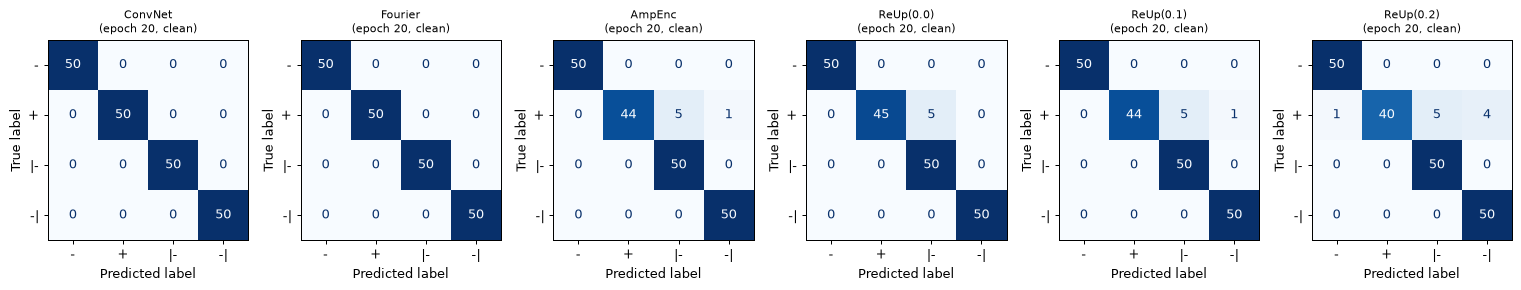

In [8]:
@torch.no_grad()
def predict(model, X):
    return model(X).argmax(1)

def acc(model, X, y):
    return (predict(model, X) == y).float().mean().item()

# classical scikit-learn baselines on the identical 256-pixel inputs (same training set, same test set)
Xtr_flat, Xte_flat = Xtr_np.reshape(len(Xtr_np), -1), Xte_np.reshape(len(Xte_np), -1)
t0 = time.time(); rf = RandomForestClassifier(n_estimators=200, random_state=SEED, n_jobs=1).fit(Xtr_flat, ytr_np); t_rf = time.time() - t0
t0 = time.time(); svc = SVC(kernel="rbf", C=1.0, gamma="scale", random_state=SEED).fit(Xtr_flat, ytr_np); t_svc = time.time() - t0
sk_models = {"RandomForest": rf, "SVC(rbf)": svc}

rows = []
for (name, ep), mod in MODELS.items():
    rows.append({"model": name, "epochs": ep, "clean test acc": acc(mod, Xte, yte), "train time (s, whole run)": TRAIN_TIME[name]})
rows.append({"model": "RandomForest", "epochs": "-", "clean test acc": rf.score(Xte_flat, yte_np), "train time (s, whole run)": t_rf})
rows.append({"model": "SVC(rbf)", "epochs": "-", "clean test acc": svc.score(Xte_flat, yte_np), "train time (s, whole run)": t_svc})
clean_df = pd.DataFrame(rows); display(clean_df.round(3))

fig, ax = plt.subplots(1, 6, figsize=(17, 3.2))
for a_, name in zip(ax, [s[0] for s in SPECS]):
    cm = confusion_matrix(yte_np, predict(MODELS[(name, E_SHORT)], Xte).numpy(), labels=range(4))
    ConfusionMatrixDisplay(cm, display_labels=CLASS_NAMES).plot(ax=a_, colorbar=False, cmap="Blues")
    a_.set_title(f"{name}\n(epoch {E_SHORT}, clean)", fontsize=9)
plt.tight_layout(); plt.show()


## 4. Attacks: PGD and accuracy under attack (Fig. 2, 3)

**PGD** (projected gradient descent, Madry et al.) searches for the perturbation `delta` with `max |delta_i| <= eps` that maximises the
loss of the true label: repeat `x <- x + alpha * sign(grad_x loss)`, then project back into the eps-box. It is a *white-box* attack: it uses the
model's own gradient. With eps = 0.1 every pixel may move by 0.1 on a [0, 1] scale. For the quantum models the gradient
with respect to the pixels flows through the simulated circuit by back-propagation (for a real device one would use parameter-shift rules).

The curves below are the notebook's version of the paper's Fig. 2: accuracy of each model on the first 100 test images after they have been perturbed
by an attack built on *that same model*.


PGD attacks on 10 models x 6 strengths finished in 381 s


,eps=0.0,eps=0.025,eps=0.05,eps=0.1,eps=0.15,eps=0.2
ConvNet (20 ep),1.00,1.00,0.98,0.26,0.00,0.00
Fourier (20 ep),1.00,1.00,0.49,0.01,0.00,0.00
AmpEnc (20 ep),0.98,0.91,0.55,0.06,0.00,0.00
AmpEnc (100 ep),0.96,0.93,0.82,0.25,0.00,0.00
ReUp(0.0) (20 ep),0.99,0.94,0.55,0.00,0.00,0.00
ReUp(0.0) (100 ep),1.00,0.90,0.11,0.00,0.00,0.00
ReUp(0.1) (20 ep),0.98,0.93,0.86,0.62,0.31,0.10
ReUp(0.1) (100 ep),0.83,0.83,0.85,0.75,0.47,0.09
ReUp(0.2) (20 ep),0.96,0.96,0.92,0.72,0.46,0.25
ReUp(0.2) (100 ep),0.75,0.72,0.69,0.58,0.42,0.08


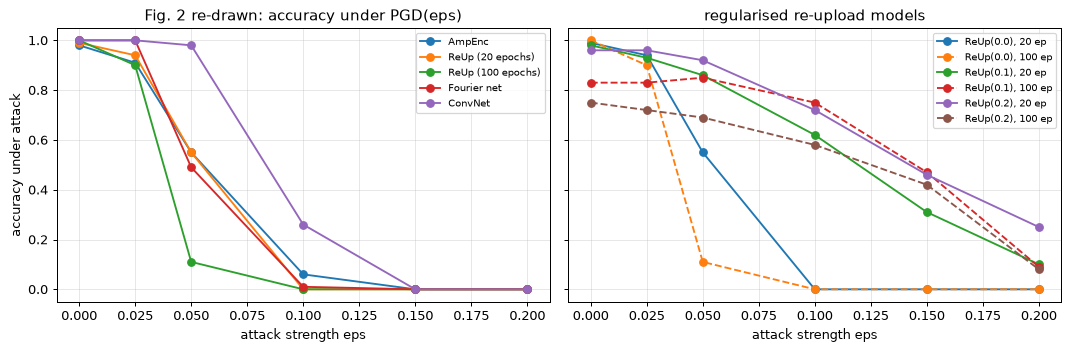

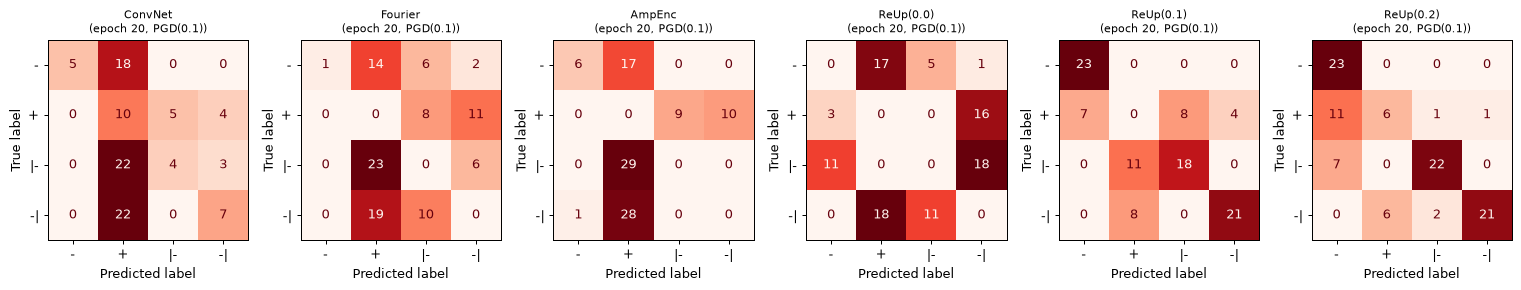

In [9]:
def pgd(model, X, y, eps, steps=None):
    """L-infinity PGD (Madry et al.), untargeted, white-box: x <- x + alpha*sign(grad CE), projected on ||x - x0||_inf <= eps.
    CHOICE: no random start, no clipping of the perturbed image to [0, 1] (the paper plots perturbations delta in [-eps, eps])."""
    if eps == 0:
        return X.clone()
    steps = steps or PGD_STEPS
    alpha = PGD_ALPHA_FACTOR * eps / steps
    xa = X.clone()
    for _ in range(steps):
        xa.requires_grad_(True)
        g, = torch.autograd.grad(F.cross_entropy(model(xa), y), xa)
        xa = X + (xa.detach() + alpha * g.sign() - X).clamp(-eps, eps)
    return xa.detach()

XA, YA = Xte[:N_ATTACK], yte[:N_ATTACK]        # the attacked images (paper: 100 images; the test set is already randomly permuted)
ADV, PGD_ACC = {}, {}                          # ADV[(name, epoch, eps)] = adversarial images; PGD_ACC[(name, epoch)][eps] = accuracy under attack
t0 = time.time()
for (name, ep), mod in MODELS.items():
    PGD_ACC[(name, ep)] = {}
    for eps in EPS_CURVE:
        ADV[(name, ep, eps)] = pgd(mod, XA, YA, eps)
        PGD_ACC[(name, ep)][eps] = acc(mod, ADV[(name, ep, eps)], YA)
print(f"PGD attacks on {len(MODELS)} models x {len(EPS_CURVE)} strengths finished in {time.time() - t0:.0f} s")

curve = pd.DataFrame({f"{n} ({e} ep)": pd.Series(PGD_ACC[(n, e)]) for (n, e) in MODELS}).T
curve.columns = [f"eps={c}" for c in curve.columns]
display(curve.round(2))

fig, ax = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
main = [("AmpEnc", E_SHORT, "AmpEnc"), ("ReUp(0.0)", E_SHORT, f"ReUp ({E_SHORT} epochs)"), ("ReUp(0.0)", E_LONG, f"ReUp ({E_LONG} epochs)"),
        ("Fourier", E_SHORT, "Fourier net"), ("ConvNet", E_SHORT, "ConvNet")]
for n, e, lab in main:
    ax[0].plot(EPS_CURVE, [PGD_ACC[(n, e)][x] for x in EPS_CURVE], "o-", label=lab)
ax[0].set_title("Fig. 2 re-drawn: accuracy under PGD(eps)")
for lam in ["ReUp(0.0)", "ReUp(0.1)", "ReUp(0.2)"]:
    for e, ls in [(E_SHORT, "-"), (E_LONG, "--")]:
        ax[1].plot(EPS_CURVE, [PGD_ACC[(lam, e)][x] for x in EPS_CURVE], ls, marker="o", label=f"{lam}, {e} ep")
ax[1].set_title("regularised re-upload models")
for a_ in ax:
    a_.set_xlabel("attack strength eps"); a_.grid(alpha=0.3); a_.legend(fontsize=8)
ax[0].set_ylabel("accuracy under attack"); plt.tight_layout(); plt.show()

# confusion matrices under the main attack PGD(0.1), attack = the positive/true-class axis is the row
fig, ax = plt.subplots(1, 6, figsize=(17, 3.2))
for a_, name in zip(ax, [s[0] for s in SPECS]):
    cm = confusion_matrix(YA.numpy(), predict(MODELS[(name, E_SHORT)], ADV[(name, E_SHORT, EPS_MAIN)]).numpy(), labels=range(4))
    ConfusionMatrixDisplay(cm, display_labels=CLASS_NAMES).plot(ax=a_, colorbar=False, cmap="Reds")
    a_.set_title(f"{name}\n(epoch {E_SHORT}, PGD({EPS_MAIN}))", fontsize=9)
plt.tight_layout(); plt.show()


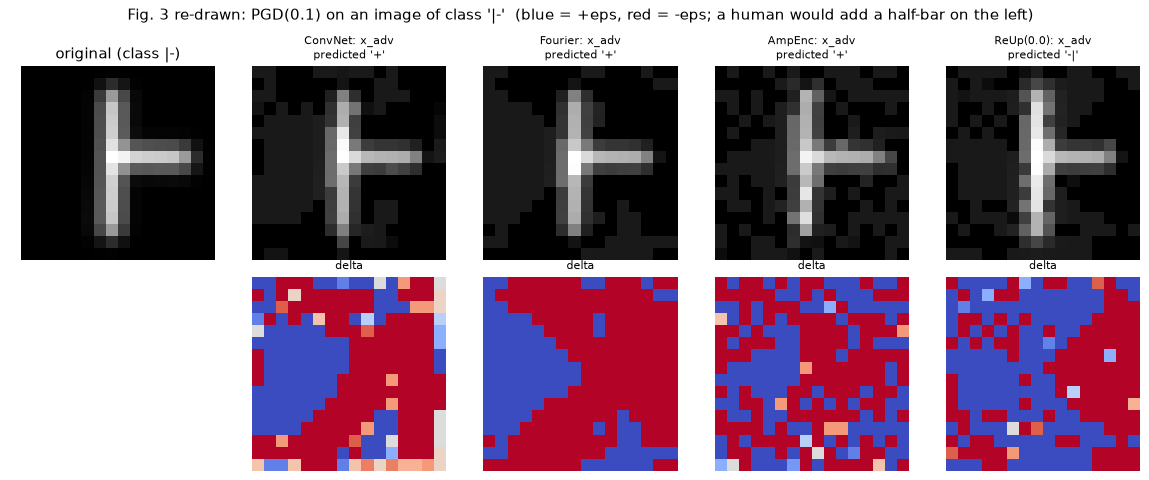

In [10]:
# Fig. 3: perturbations delta = x_adv - x of PGD(0.1) on one image of class '|-' for each architecture
cands = [i for i in range(N_ATTACK) if YA[i] == 2 and all(predict(MODELS[(n, E_SHORT)], XA[i:i + 1]).item() == 2
                                                        for n in ["ConvNet", "Fourier", "AmpEnc", "ReUp(0.0)"])]
i0 = cands[0] if cands else int(np.flatnonzero(YA.numpy() == 2)[0])
fig, ax = plt.subplots(2, 5, figsize=(13, 5.4))
ax[0, 0].imshow(XA[i0], cmap="gray", vmin=0, vmax=1); ax[0, 0].set_title("original (class |-)"); ax[1, 0].axis("off")
for j, n in enumerate(["ConvNet", "Fourier", "AmpEnc", "ReUp(0.0)"], start=1):
    mod = MODELS[(n, E_SHORT)]
    xa = ADV[(n, E_SHORT, EPS_MAIN)][i0:i0 + 1]
    pred = CLASS_NAMES[predict(mod, xa).item()]
    ax[0, j].imshow(xa[0], cmap="gray", vmin=0, vmax=1); ax[0, j].set_title(f"{n}: x_adv\npredicted '{pred}'", fontsize=9)
    im = ax[1, j].imshow((xa[0] - XA[i0]).numpy(), cmap="coolwarm_r", vmin=-EPS_MAIN, vmax=EPS_MAIN); ax[1, j].set_title("delta", fontsize=9)
for a_ in ax.ravel():
    a_.axis("off")
plt.suptitle("Fig. 3 re-drawn: PGD(0.1) on an image of class '|-'  (blue = +eps, red = -eps; a human would add a half-bar on the left)")
plt.tight_layout(); plt.show()


## 5. Transfer attacks across the quantum / classical boundary (Fig. 4)

A **transfer attack** takes the perturbed images generated on a *source* model and feeds them to a different *target* model whose
gradients the attacker never used. If accuracy stays high, the attack did not transfer; if it collapses, both models rely on the same fragile features.
The paper's headline question, "are quantum models more robust?", is answered by the rows and columns of this matrix: the
diagonal is the white-box case, off-diagonal entries are transfers. Rows and columns follow the paper's order; AmpEnc is last. The two scikit-learn
baselines are shown as extra columns (their accuracy under the same transferred images).


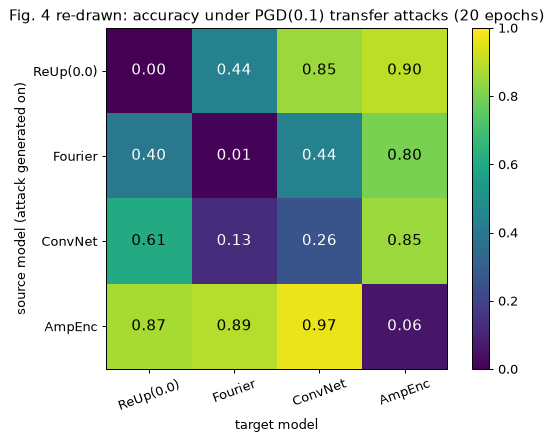

,to ReUp(0.0),to Fourier,to ConvNet,to AmpEnc,"to RandomForest (baseline, black box)","to SVC(rbf) (baseline, black box)"
from ReUp(0.0),0.00,0.44,0.85,0.90,0.33,1.00
from Fourier,0.40,0.01,0.44,0.80,0.17,0.98
from ConvNet,0.61,0.13,0.26,0.85,0.13,1.00
from AmpEnc,0.87,0.89,0.97,0.06,0.18,1.00


In [11]:
# Fig. 4: transfer matrix. Row i = source model whose PGD(0.1) images are used; column j = target model that classifies them.
ORDER = ["ReUp(0.0)", "Fourier", "ConvNet", "AmpEnc"]
TM = np.array([[acc(MODELS[(tgt, E_SHORT)], ADV[(src, E_SHORT, EPS_MAIN)], YA) for tgt in ORDER] for src in ORDER])
sk_cols = {k: np.array([m.score(ADV[(src, E_SHORT, EPS_MAIN)].numpy().reshape(N_ATTACK, -1), YA.numpy()) for src in ORDER]) for k, m in sk_models.items()}

fig, ax = plt.subplots(figsize=(6.6, 5))
im = ax.imshow(TM, cmap="viridis", vmin=0, vmax=1)
for i in range(4):
    for j in range(4):
        ax.text(j, i, f"{TM[i, j]:.2f}", ha="center", va="center", color="w" if TM[i, j] < 0.6 else "k", fontsize=12)
ax.set_xticks(range(4)); ax.set_xticklabels(ORDER, rotation=20); ax.set_yticks(range(4)); ax.set_yticklabels(ORDER)
ax.set_xlabel("target model"); ax.set_ylabel("source model (attack generated on)")
ax.set_title(f"Fig. 4 re-drawn: accuracy under PGD({EPS_MAIN}) transfer attacks ({E_SHORT} epochs)"); plt.colorbar(im); plt.tight_layout(); plt.show()

tdf = pd.DataFrame(TM, index=[f"from {s}" for s in ORDER], columns=[f"to {t}" for t in ORDER])
for k, v in sk_cols.items():
    tdf[f"to {k} (baseline, black box)"] = v
display(tdf.round(2))


## 6. Does Lipschitz regularisation help? (Fig. 5, 6, 7)

The re-upload circuit's output changes with the input at a rate bounded by `L = 2 ||M|| sum_j ||w_j|| ||H_j||`: the larger the encoding
weights, the more a small pixel change can swing the output. Adding `lambda * sum ||w_j||^2 ||H_j||^2` to the loss keeps the weights small, so
**ReUp(0.1)** and **ReUp(0.2)** should have smaller bounds. Figure 5 attacks these models with perturbations crafted on the Fourier net; Figure 6
reverses the direction (perturbations crafted on the quantum models, applied to the Fourier net); Figure 7 looks at the perturbation patterns.


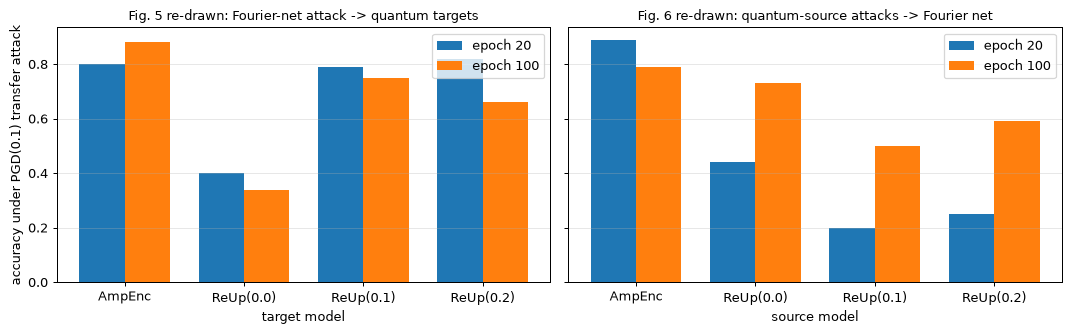

,"Fig5: Fourier -> target, ep 20","Fig5, ep 100","Fig6: source -> Fourier, ep 20","Fig6, ep 100"
AmpEnc,0.80,0.88,0.89,0.79
ReUp(0.0),0.40,0.34,0.44,0.73
ReUp(0.1),0.79,0.75,0.20,0.50
ReUp(0.2),0.82,0.66,0.25,0.59


In [12]:
# Fig. 5: attack generated on the Fourier net -> AmpEnc and ReUp(lambda) models (epoch E_SHORT and E_LONG)
T5 = ["AmpEnc", "ReUp(0.0)", "ReUp(0.1)", "ReUp(0.2)"]
adv_f = ADV[("Fourier", E_SHORT, EPS_MAIN)]
F5 = {ep: [acc(MODELS[(t, ep)], adv_f, YA) for t in T5] for ep in (E_SHORT, E_LONG)}
# Fig. 6: attacks generated on AmpEnc / ReUp(lambda) (epoch E_SHORT and E_LONG) -> the Fourier net trained for E_SHORT epochs
F6 = {ep: [acc(MODELS[("Fourier", E_SHORT)], ADV[(s, ep, EPS_MAIN)], YA) for s in T5] for ep in (E_SHORT, E_LONG)}

fig, ax = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
xs = np.arange(4); wd = 0.38
for a_, D, ttl, xl in [(ax[0], F5, "Fig. 5 re-drawn: Fourier-net attack -> quantum targets", "target model"),
                       (ax[1], F6, "Fig. 6 re-drawn: quantum-source attacks -> Fourier net", "source model")]:
    a_.bar(xs - wd / 2, D[E_SHORT], wd, label=f"epoch {E_SHORT}"); a_.bar(xs + wd / 2, D[E_LONG], wd, label=f"epoch {E_LONG}")
    a_.set_xticks(xs); a_.set_xticklabels(T5); a_.set_xlabel(xl); a_.set_title(ttl, fontsize=10); a_.legend(); a_.grid(axis="y", alpha=0.3)
ax[0].set_ylabel("accuracy under PGD(0.1) transfer attack"); plt.tight_layout(); plt.show()
display(pd.DataFrame({"Fig5: Fourier -> target, ep %d" % E_SHORT: F5[E_SHORT], "Fig5, ep %d" % E_LONG: F5[E_LONG],
                      "Fig6: source -> Fourier, ep %d" % E_SHORT: F6[E_SHORT], "Fig6, ep %d" % E_LONG: F6[E_LONG]}, index=T5).round(2))


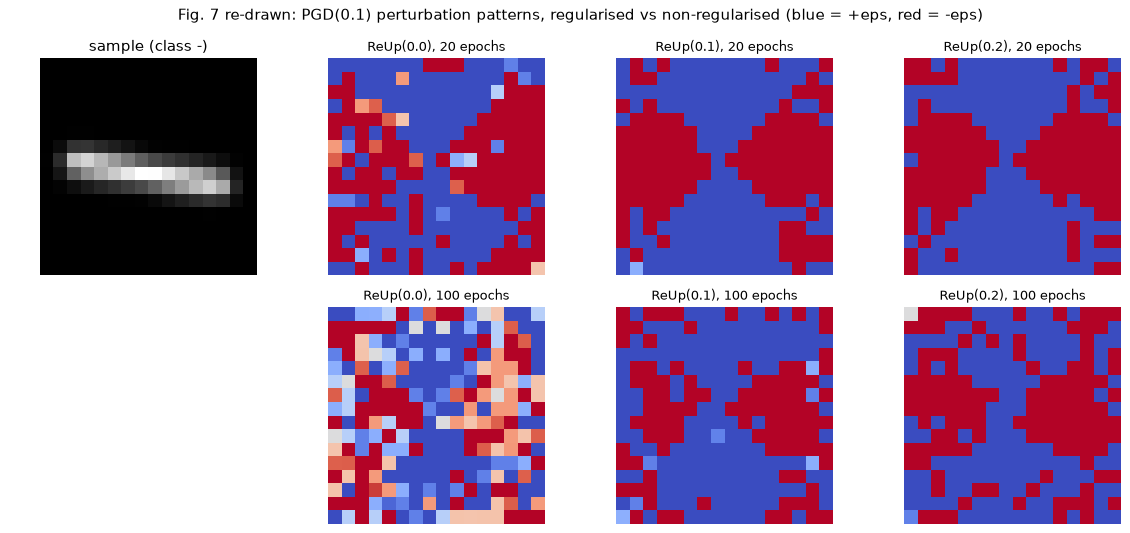

,model,epochs,successful attacks,semantic alignment (0 = noise)
0,ConvNet,20,74,0.370
1,Fourier,20,99,0.342
2,AmpEnc,20,94,0.253
3,AmpEnc,100,75,0.258
4,ReUp(0.0),20,100,0.233
5,ReUp(0.0),100,100,0.260
6,ReUp(0.1),20,38,0.304
7,ReUp(0.1),100,25,0.353
8,ReUp(0.2),20,28,0.360
9,ReUp(0.2),100,42,0.157


In [13]:
# Fig. 7: perturbation patterns of the re-upload models for one image of class '-' (the attack should add a vertical bar)
j0 = int(np.flatnonzero(YA.numpy() == 0)[0])
fig, ax = plt.subplots(2, 4, figsize=(13, 6))
ax[0, 0].imshow(XA[j0], cmap="gray", vmin=0, vmax=1); ax[0, 0].set_title("sample (class -)"); ax[1, 0].axis("off")
for r, ep in enumerate((E_SHORT, E_LONG)):
    for c, lam in enumerate(["ReUp(0.0)", "ReUp(0.1)", "ReUp(0.2)"]):
        d_ = (ADV[(lam, ep, EPS_MAIN)][j0] - XA[j0]).numpy()
        ax[r, c + 1].imshow(d_, cmap="coolwarm_r", vmin=-EPS_MAIN, vmax=EPS_MAIN); ax[r, c + 1].set_title(f"{lam}, {ep} epochs", fontsize=10)
for a_ in ax.ravel():
    a_.axis("off")
plt.suptitle("Fig. 7 re-drawn: PGD(0.1) perturbation patterns, regularised vs non-regularised (blue = +eps, red = -eps)"); plt.tight_layout(); plt.show()

# --- A number for what the paper judges by eye (our addition): does the perturbation draw the label change (add ink where the predicted class has ink)?
def focus_lift(name, ep, eps=EPS_MAIN):
    """'Semantic alignment' of the attack: for every successful attack (true class a -> predicted class b) the cosine similarity between the
    perturbation delta and the 'meaningful change' CLASS_MEAN[b] - CLASS_MEAN[a] (add ink where class b has ink and a does not, remove it
    where the opposite holds).  0 = unrelated to the label change (noise), 1 = delta is exactly the change a human would draw."""
    mod = MODELS[(name, ep)]; xa = ADV[(name, ep, eps)]
    pred = predict(mod, xa).numpy(); sims = []
    for i in range(N_ATTACK):
        a_, b_ = int(YA[i]), int(pred[i])
        if a_ == b_:
            continue
        d_ = (xa[i] - XA[i]).numpy().ravel(); t_ = (CLASS_MEAN[b_] - CLASS_MEAN[a_]).ravel()
        sims.append(float(d_ @ t_ / (np.linalg.norm(d_) * np.linalg.norm(t_) + 1e-12)))
    return (float(np.mean(sims)) if sims else float("nan")), len(sims)

FOCUS = {(n, e): focus_lift(n, e) for (n, e) in MODELS}
fdf = pd.DataFrame([{"model": n, "epochs": e, "successful attacks": k, "semantic alignment (0 = noise)": round(v, 3)} for (n, e), (v, k) in FOCUS.items()])
display(fdf)


## 7. Lipschitz bounds (Table I)

A function with Lipschitz constant `L` changes its output by at most `L * ||x - x'||_2` when the input moves from `x` to `x'`; a *low* bound is a
certificate of robustness, a high bound proves nothing. We compute

* **ReUp:** the Berberich et al. bound, in closed form from the trained encoding weights: `L = sum_j |w_j|` (because `2 ||M|| ||H_j|| = 1` for Pauli-Z read-out and Rot generators `sigma / 2`);
* **Fourier net:** `||W1||_2 ||W0||_2`, a product of spectral norms (the paper uses the tighter LipSDP);
* **ConvNet:** the spectral norm of the convolution written as an 864 x 256 matrix times the spectral norm of the linear layer, exactly the paper's Toeplitz route (also an upper bound);
* **every model:** the largest spectral norm of the output Jacobian over the test images, a *lower* bound on the true local Lipschitz constant, to see how loose the upper bounds are.

The bounds are for the vector of the four outputs (logits for classical nets, `<Z>` values for the circuits), not for the softmax.


,model,epochs,our upper bound,paper Table I,paper epochs,max local Jacobian norm (lower bound),mean local Jacobian norm
0,ConvNet,20,23.47,20.24,20,8.44,7.81
1,Fourier,20,9.66,25.38,20,9.23,6.44
2,AmpEnc,20,NaN,NaN,20,0.66,0.44
3,AmpEnc,100,NaN,NaN,100,0.65,0.44
4,ReUp(0.0),20,120.51,73.11,20,1.43,0.90
5,ReUp(0.0),100,230.90,106.33,100,3.18,1.46
6,ReUp(0.1),20,22.85,18.18,20,0.85,0.52
7,ReUp(0.1),100,20.35,19.77,100,1.58,1.05
8,ReUp(0.2),20,14.39,13.50,20,0.55,0.46
9,ReUp(0.2),100,12.17,11.83,100,2.15,1.34


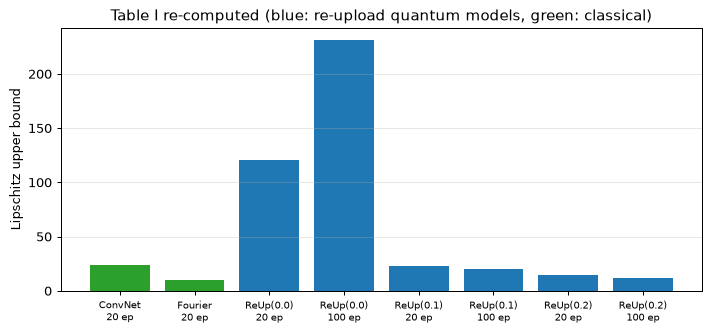

In [14]:
# ---- Lipschitz bounds (Table I) ----
def lip_reup(m):
    """Eq. (7): L = 2 ||M|| sum_j ||w_j|| ||H_j||; here ||M|| = 1 (one Pauli-Z), ||H_j|| = 1/2 and every weight w_j is a scalar acting on one pixel."""
    return float(2 * 1.0 * (0.5 * m.w.abs()).sum())

def lip_fourier(m):
    """Upper bound ||W1||_2 ||W0||_2.  (The 64 x 32 sin/cos block has Jacobian [diag(cos u); -diag(sin u)] W0 whose norm is exactly <= ||W0||_2.)
    LipSDP (the paper's tool) is tighter but needs an SDP solver; this spectral-norm product is the classical 'Szegedy' bound that LipSDP refines."""
    with torch.no_grad():
        return float(torch.linalg.matrix_norm(m.enc.weight, 2) * torch.linalg.matrix_norm(m.out.weight, 2))

def lip_conv(m):
    """Toeplitz representation of the 5x5 convolution (paper App. C): spectral norm of the 864 x 256 matrix times that of the linear layer
    (ReLU and max-pool are 1-Lipschitz)."""
    with torch.no_grad():
        T = F.conv2d(torch.eye(IMG * IMG).reshape(IMG * IMG, 1, IMG, IMG), m.conv.weight).flatten(1)   # row i = response to pixel i
        return float(torch.linalg.matrix_norm(T, 2) * torch.linalg.matrix_norm(m.fc.weight, 2))

def local_lip(model, X):
    """Empirical *lower* bound: largest spectral norm of the 4 x 256 Jacobian of the model output over the test images."""
    X = X.clone().requires_grad_(True); out = model(X)
    J = torch.stack([torch.autograd.grad(out[:, k].sum(), X, retain_graph=True)[0].flatten(1) for k in range(4)], 1)
    s = torch.linalg.matrix_norm(J, 2)
    return float(s.max()), float(s.mean())

LIPS = {}
for (n, e), mod in MODELS.items():
    ub = lip_reup(mod) if n.startswith("ReUp") else lip_fourier(mod) if n == "Fourier" else lip_conv(mod) if n == "ConvNet" else float("nan")
    lo, lo_mean = local_lip(mod, XA)
    LIPS[(n, e)] = dict(upper=ub, local_max=lo, local_mean=lo_mean)

PAPER_TABLE_I = {("ReUp(0.0)", 20): 73.11, ("ReUp(0.0)", 100): 106.33, ("ReUp(0.1)", 20): 18.18, ("ReUp(0.1)", 100): 19.77,
                 ("ReUp(0.2)", 20): 13.50, ("ReUp(0.2)", 100): 11.83, ("Fourier", 20): 25.38, ("ConvNet", 20): 20.24}
rows = []
for (n, e), mod in MODELS.items():
    pe = {E_SHORT: 20, E_LONG: 100}[e]
    rows.append({"model": n, "epochs": e, "our upper bound": LIPS[(n, e)]["upper"], "paper Table I": PAPER_TABLE_I.get((n, pe), np.nan), "paper epochs": pe,
                 "max local Jacobian norm (lower bound)": LIPS[(n, e)]["local_max"], "mean local Jacobian norm": LIPS[(n, e)]["local_mean"]})
lipdf = pd.DataFrame(rows); display(lipdf.round(2))

fig, ax = plt.subplots(figsize=(8, 3.8))
lab = [f"{n}\n{e} ep" for (n, e) in MODELS if not np.isnan(LIPS[(n, e)]["upper"])]
val = [LIPS[(n, e)]["upper"] for (n, e) in MODELS if not np.isnan(LIPS[(n, e)]["upper"])]
ax.bar(range(len(val)), val, color=["tab:blue" if l.startswith("ReUp") else "tab:green" for l in lab]); ax.set_xticks(range(len(val))); ax.set_xticklabels(lab, fontsize=8)
ax.set_ylabel("Lipschitz upper bound"); ax.set_title("Table I re-computed (blue: re-upload quantum models, green: classical)"); ax.grid(axis="y", alpha=0.3)
plt.tight_layout(); plt.show()


## 8. Stability over seeds

The paper reports single runs for its attack experiments. Here the key measurements (clean accuracy, accuracy under PGD(0.1), Lipschitz
bound) are repeated with different initialisation seeds so you can see how much of any difference between models is just luck.


In [15]:
# ---- repeat the key measurements over several initialisation seeds (cheap models: N_CLASSICAL_SEEDS, quantum: N_Q_EXTRA_SEEDS extra) ----
def seed_run(name, seed):
    _, fr = train_model(name, seed, E_SHORT, snaps={E_SHORT})
    mod = fr[E_SHORT]
    adv = pgd(mod, XA, YA, EPS_MAIN)
    ub = lip_reup(mod) if name.startswith("ReUp") else lip_fourier(mod) if name == "Fourier" else lip_conv(mod) if name == "ConvNet" else float("nan")
    return dict(clean=acc(mod, Xte, yte), pgd=acc(mod, adv, YA), lip=ub)

SEED_RES = {n: [dict(clean=acc(MODELS[(n, E_SHORT)], Xte, yte), pgd=PGD_ACC[(n, E_SHORT)][EPS_MAIN], lip=LIPS[(n, E_SHORT)]["upper"])]
            for n in ["ConvNet", "Fourier", "AmpEnc", "ReUp(0.0)", "ReUp(0.2)"]}
t0 = time.time()
for n in ["ConvNet", "Fourier"]:
    for k in range(1, N_CLASSICAL_SEEDS):
        SEED_RES[n].append(seed_run(n, SEED + k))
for n in ["AmpEnc", "ReUp(0.0)", "ReUp(0.2)"]:
    for k in range(1, N_Q_EXTRA_SEEDS + 1):
        SEED_RES[n].append(seed_run(n, SEED + k))
print(f"extra seeds finished in {time.time() - t0:.0f} s")

def ms(v):
    v = np.array(v, float); return f"{v.mean():.3f} +- {v.std():.3f}" if len(v) > 1 else f"{v[0]:.3f}"
sdf = pd.DataFrame([{"model": n, "seeds": len(r), "clean acc": ms([x["clean"] for x in r]), f"acc under PGD({EPS_MAIN})": ms([x["pgd"] for x in r]),
                     "Lipschitz upper bound": ms([x["lip"] for x in r])} for n, r in SEED_RES.items()])
display(sdf)


extra seeds finished in 915 s


,model,seeds,clean acc,acc under PGD(0.1),Lipschitz upper bound
0,ConvNet,5,1.000 +- 0.000,0.334 +- 0.047,22.625 +- 1.287
1,Fourier,5,1.000 +- 0.000,0.004 +- 0.005,9.747 +- 0.296
2,AmpEnc,3,0.980 +- 0.011,0.067 +- 0.009,nan +- nan
3,ReUp(0.0),3,0.983 +- 0.012,0.007 +- 0.009,123.209 +- 4.627
4,ReUp(0.2),3,0.965 +- 0.015,0.727 +- 0.017,14.920 +- 0.397


## 9. Side-by-side comparison with the paper

The paper prints numbers only for Table I and one sentence of the transfer section ("a degradation ... by 0.5"). Everything else is a
bar chart or heat map, so those claims are tested here as **orderings** (is A more robust than B?), exactly the way the paper argues. Verdicts:
*reproduced* = the statement holds in this notebook (numbers within the stated tolerance, ordering as claimed); *not reached* / *exceeded* =
it does not, with the gap; *cannot be checked* = would need the paper's data or code. The tolerances for the numeric claims
(+-25 % relative for Table I, +-0.15 accuracy for the "0.5" statement) are our choice, since 100-image attack sets and different data
generators cannot reproduce a digit-level figure.


In [16]:
# ---- side-by-side comparison with the paper: one verdict per checkable claim ----
def tr(src, ep_s, tgt, ep_t, eps=EPS_MAIN):
    return acc(MODELS[(tgt, ep_t)], ADV[(src, ep_s, eps)], YA)

def verdict_rel(ours, paper, tol=0.25):
    r = ours / paper
    return "reproduced" if abs(r - 1) <= tol else ("exceeded" if r > 1 else "not reached") + f" (ratio {r:.2f})"

C = []   # (claim, paper, notebook, verdict)
def add(claim, paper, ours, verdict):
    C.append({"claim": claim, "paper": paper, "this notebook": ours, "verdict": verdict})

# --- model definitions
add("ConvNet has 1024 parameters (App. A)", "1024", str(n_params(ConvNet())), "reproduced" if n_params(ConvNet()) == 1024 else "not reached")
add("ReUp model has 1536 trainable parameters", "1536", str(n_params(ReUp())), "reproduced" if n_params(ReUp()) == 1536 else "not reached")

# --- training (Fig. 11)
e10 = min(10, E_SHORT)
accs10 = {n: HIST[n][e10 - 1] for n in ["ConvNet", "Fourier", "AmpEnc", "ReUp(0.0)"]}
add(f"Validation accuracy >= 99 % after {e10} epochs (unregularised models, Fig. 11)", ">= 0.99 for all four",
    ", ".join(f"{k}: {v:.2f}" for k, v in accs10.items()), "reproduced" if min(accs10.values()) >= 0.99 else "not reached (min %.2f)" % min(accs10.values()))
accsS = {n: acc(MODELS[(n, E_SHORT)], Xte, yte) for n in ["ConvNet", "Fourier", "AmpEnc", "ReUp(0.0)"]}
add(f"Near-perfect accuracy after {E_SHORT} epochs (the attacked models)", "\"near-perfect\"", ", ".join(f"{k}: {v:.2f}" for k, v in accsS.items()),
    "reproduced" if min(accsS.values()) >= 0.97 else "not reached (min %.2f)" % min(accsS.values()))

# --- Fig. 2
ratio = {n: PGD_ACC[(n, e)][0.2] / max(PGD_ACC[(n, e)][0.0], 1e-9) for n, e, _ in main}
add("All models deteriorate drastically under PGD(eps <= 0.2) (Fig. 2)", "strong drop for all five curves",
    ", ".join(f"{lab}: {PGD_ACC[(n, e)][0.2]:.2f}" for n, e, lab in main) + " at eps=0.2",
    "reproduced" if max(ratio.values()) <= 0.5 else "not reached (%d of 5 curves fall below half of clean accuracy)" % sum(v <= 0.5 for v in ratio.values()))
better = sum(PGD_ACC[("ReUp(0.0)", E_SHORT)][x] > PGD_ACC[("ReUp(0.0)", E_LONG)][x] for x in EPS_LIST)
worse = sum(PGD_ACC[("ReUp(0.0)", E_SHORT)][x] < PGD_ACC[("ReUp(0.0)", E_LONG)][x] for x in EPS_LIST)
add(f"ReUp trained {E_LONG} epochs is less robust than after {E_SHORT} epochs (Fig. 2)", f"{E_LONG}-epoch curve below {E_SHORT}-epoch curve",
    ", ".join(f"eps {x}: {PGD_ACC[('ReUp(0.0)', E_SHORT)][x]:.2f} vs {PGD_ACC[('ReUp(0.0)', E_LONG)][x]:.2f}" for x in EPS_LIST),
    ("reproduced" if (better >= 1 and worse == 0) else "not reached") + f" ({better} strengths lower, {worse} higher, {len(EPS_LIST) - better - worse} tied at ~0 accuracy)")
add("Regularised models lose validation accuracy (Fig. 11 caption: the regularisation term 'takes over')", f"val acc of ReUp(0.2) below ReUp(0.0) after {E_LONG} epochs",
    f"{HIST['ReUp(0.2)'][-1]:.2f} vs {HIST['ReUp(0.0)'][-1]:.2f}", "reproduced" if HIST["ReUp(0.2)"][-1] < HIST["ReUp(0.0)"][-1] else "not reached")
diag = {n: PGD_ACC[(n, E_SHORT)][EPS_MAIN] for n in ORDER}
add("ConvNet keeps a relatively high accuracy under its own PGD(0.1) attack (Fig. 4 diagonal)", "ConvNet diagonal entry above the other models'",
    ", ".join(f"{k}: {v:.2f}" for k, v in diag.items()), "reproduced" if diag["ConvNet"] > np.mean([diag[k] for k in ORDER if k != "ConvNet"]) else "not reached")

# --- Fig. 4 transfer
clean_reup = acc(MODELS[("ReUp(0.0)", E_SHORT)], Xte, yte)
drop = clean_reup - tr("Fourier", E_SHORT, "ReUp(0.0)", E_SHORT)
add("Attack from the Fourier net degrades the ReUp model by about 0.5 (text of Sec. IV-D)", "0.5", f"{drop:.2f}", "reproduced" if abs(drop - 0.5) <= 0.15 else ("exceeded" if drop > 0.5 else "not reached") + f" (gap {drop - 0.5:+.2f}; tolerance +-0.15 is our choice)")
a_fr, a_rf = tr("Fourier", E_SHORT, "ReUp(0.0)", E_SHORT), tr("ReUp(0.0)", E_SHORT, "Fourier", E_SHORT)
add("Fourier -> ReUp transfer is stronger than ReUp -> Fourier (entry[2,1] vs entry[1,2])", "ReUp acc under Fourier attack < Fourier acc under ReUp attack",
    f"{a_fr:.2f} vs {a_rf:.2f}", "reproduced" if a_fr < a_rf else "not reached")
offdiag = lambda M, j=None, i=None: np.mean([M[a, b] for a in range(4) for b in range(4) if a != b and (j is None or b == j) and (i is None or a == i)])
colm = [offdiag(TM, j=j) for j in range(4)]; rowm = [offdiag(TM, i=i) for i in range(4)]
add("AmpEnc is robust to transfer attacks from the other models (last column of Fig. 4)", "AmpEnc column has the highest accuracy",
    ", ".join(f"{ORDER[j]}: {colm[j]:.2f}" for j in range(4)), "reproduced" if colm[3] >= max(colm[:3]) else "not reached")
add("Attacks generated on AmpEnc do not transfer to any other model (last row of Fig. 4)", "AmpEnc row has the highest accuracy",
    ", ".join(f"{ORDER[i]}: {rowm[i]:.2f}" for i in range(4)), "reproduced" if rowm[3] >= max(rowm[:3]) else "not reached")

# --- Fig. 5 / 6 regularisation
for ep in (E_SHORT, E_LONG):
    a0, a2 = F5[ep][1], F5[ep][3]
    add(f"Regularisation protects ReUp against Fourier-net attacks, {ep}-epoch models (Fig. 5)", "ReUp(0.2) more accurate than ReUp(0.0)", f"{a2:.2f} vs {a0:.2f}", "reproduced" if a2 > a0 else "not reached")
add("Attacks from AmpEnc leave the Fourier net almost unharmed (Fig. 6, first bar)", "high accuracy", f"{F6[E_SHORT][0]:.2f}", "reproduced" if F6[E_SHORT][0] >= 0.8 else "not reached (threshold 0.8 is our choice)")
for ep in (E_SHORT, E_LONG):
    f0, f2 = F6[ep][1], F6[ep][3]
    add(f"Attacks from stronger-regularised ReUp ({ep} epochs) fool the Fourier net more (Fig. 6)", "Fourier accuracy falls as lambda grows", f"lambda 0.0: {f0:.2f}, 0.2: {f2:.2f}", "reproduced" if f2 < f0 else "not reached")
add("Attacks from the long-trained ReUp(0.0) are less successful on the Fourier net (Fig. 6)", f"{E_LONG}-epoch source weaker than {E_SHORT}-epoch source",
    f"Fourier acc {F6[E_LONG][1]:.2f} vs {F6[E_SHORT][1]:.2f}", "reproduced" if F6[E_LONG][1] > F6[E_SHORT][1] else "not reached")

# --- Fig. 7: perturbation patterns
fl = {k: v[0] for k, v in FOCUS.items()}
NOTE = " (semantic alignment is our own metric, the paper judges by eye)"
add("Perturbations on AmpEnc are the most scattered (Fig. 3 discussion)", "lowest semantic alignment among the models", ", ".join(f"{n}: {fl[(n, E_SHORT)]:.2f}" for n in ["ConvNet", "Fourier", "AmpEnc", "ReUp(0.0)"]),
    ("reproduced" if fl[("AmpEnc", E_SHORT)] <= min(fl[(n, E_SHORT)] for n in ["ConvNet", "Fourier", "ReUp(0.0)"]) else "not reached") + NOTE)
add(f"Long training makes the unregularised ReUp pattern noisier (Fig. 7)", f"alignment({E_LONG} ep) < alignment({E_SHORT} ep)", f"{fl[('ReUp(0.0)', E_LONG)]:.2f} vs {fl[('ReUp(0.0)', E_SHORT)]:.2f}",
    ("reproduced" if fl[("ReUp(0.0)", E_LONG)] < fl[("ReUp(0.0)", E_SHORT)] else "not reached") + NOTE)
add("Regularisation gives cleaner (better aligned) patterns (Fig. 7)", "alignment(lambda=0.2) > alignment(lambda=0.0)", f"{fl[('ReUp(0.2)', E_SHORT)]:.2f} vs {fl[('ReUp(0.0)', E_SHORT)]:.2f} ({E_SHORT} ep); {fl[('ReUp(0.2)', E_LONG)]:.2f} vs {fl[('ReUp(0.0)', E_LONG)]:.2f} ({E_LONG} ep)",
    ("reproduced" if fl[("ReUp(0.2)", E_SHORT)] > fl[("ReUp(0.0)", E_SHORT)] and fl[("ReUp(0.2)", E_LONG)] > fl[("ReUp(0.0)", E_LONG)] else "not reached") + NOTE)

# --- Table I
for (n, pe), pv in PAPER_TABLE_I.items():
    e = {20: E_SHORT, 100: E_LONG}[pe]
    if (n, e) in LIPS:
        same_budget = (e == pe)
        add(f"Table I: Lipschitz bound of {n}, {pe} epochs" + ("" if same_budget else f" (here {e} epochs)"), f"{pv}", f"{LIPS[(n, e)]['upper']:.2f}",
            verdict_rel(LIPS[(n, e)]["upper"], pv) if same_budget else "cannot be checked (FAST_MODE trains for a different number of epochs)")
Lb = lambda n, e: LIPS[(n, e)]["upper"]
add("L grows with training time for unregularised ReUp", f"L({E_LONG} ep) > L({E_SHORT} ep)", f"{Lb('ReUp(0.0)', E_LONG):.1f} vs {Lb('ReUp(0.0)', E_SHORT):.1f}", "reproduced" if Lb("ReUp(0.0)", E_LONG) > Lb("ReUp(0.0)", E_SHORT) else "not reached")
add("Regularisation lowers L strongly (lambda = 0.1, 0.2 vs 0)", "factor ~4 or more", f"{Lb('ReUp(0.0)', E_SHORT) / Lb('ReUp(0.1)', E_SHORT):.1f}x, {Lb('ReUp(0.0)', E_SHORT) / Lb('ReUp(0.2)', E_SHORT):.1f}x",
    "reproduced" if Lb("ReUp(0.0)", E_SHORT) / Lb("ReUp(0.2)", E_SHORT) >= 3 else "not reached")
add("Regularised ReUp bounds fall to or below the classical models' bounds", "L(ReUp(0.2)) < L(Fourier), L(ConvNet)", f"{Lb('ReUp(0.2)', E_SHORT):.1f} vs {Lb('Fourier', E_SHORT):.1f}, {Lb('ConvNet', E_SHORT):.1f}",
    "reproduced" if Lb("ReUp(0.2)", E_SHORT) < min(Lb("Fourier", E_SHORT), Lb("ConvNet", E_SHORT)) else "not reached")
g0 = abs(Lb("ReUp(0.0)", E_LONG) - Lb("ReUp(0.0)", E_SHORT)) / Lb("ReUp(0.0)", E_SHORT); g2 = abs(Lb("ReUp(0.2)", E_LONG) - Lb("ReUp(0.2)", E_SHORT)) / Lb("ReUp(0.2)", E_SHORT)
add("Regularisation reduces the effect of training time on L", "relative change over training much smaller for lambda = 0.2", f"{g2:.2f} vs {g0:.2f}", "reproduced" if g2 < g0 else "not reached")

cmp_df = pd.DataFrame(C)
pd.set_option("display.max_colwidth", 90)
display(cmp_df)
print("\nsummary:", cmp_df["verdict"].str.extract(r"^(reproduced|not reached|exceeded|cannot be checked)")[0].value_counts().to_dict())
print("(tolerances: relative +-25 % for Table I, +-0.15 accuracy for the 'by 0.5' statement; every other claim in the paper is qualitative and tested as an ordering.)")


,claim,paper,this notebook,verdict
0,ConvNet has 1024 parameters (App. A),1024,1024,reproduced
1,ReUp model has 1536 trainable parameters,1536,1536,reproduced
2,"Validation accuracy >= 99 % after 10 epochs (unregularised models, Fig. 11)",>= 0.99 for all four,"ConvNet: 1.00, Fourier: 1.00, AmpEnc: 0.94, ReUp(0.0): 0.99",not reached (min 0.94)
3,Near-perfect accuracy after 20 epochs (the attacked models),"""near-perfect""","ConvNet: 1.00, Fourier: 1.00, AmpEnc: 0.97, ReUp(0.0): 0.98",reproduced
4,All models deteriorate drastically under PGD(eps <= 0.2) (Fig. 2),strong drop for all five curves,"AmpEnc: 0.00, ReUp (20 epochs): 0.00, ReUp (100 epochs): 0.00, Fourier net: 0.00, Conv...",reproduced
5,ReUp trained 100 epochs is less robust than after 20 epochs (Fig. 2),100-epoch curve below 20-epoch curve,"eps 0.05: 0.55 vs 0.11, eps 0.1: 0.00 vs 0.00, eps 0.2: 0.00 vs 0.00","reproduced (1 strengths lower, 0 higher, 2 tied at ~0 accuracy)"
6,Regularised models lose validation accuracy (Fig. 11 caption: the regularisation term ...,val acc of ReUp(0.2) below ReUp(0.0) after 100 epochs,0.80 vs 1.00,reproduced
7,ConvNet keeps a relatively high accuracy under its own PGD(0.1) attack (Fig. 4 diagonal),ConvNet diagonal entry above the other models',"ReUp(0.0): 0.00, Fourier: 0.01, ConvNet: 0.26, AmpEnc: 0.06",reproduced
8,Attack from the Fourier net degrades the ReUp model by about 0.5 (text of Sec. IV-D),0.5,0.58,reproduced
9,"Fourier -> ReUp transfer is stronger than ReUp -> Fourier (entry[2,1] vs entry[1,2])",ReUp acc under Fourier attack < Fourier acc under ReUp attack,0.40 vs 0.44,reproduced



summary: {'reproduced': 24, 'not reached': 6, 'exceeded': 3}
(tolerances: relative +-25 % for Table I, +-0.15 accuracy for the 'by 0.5' statement; every other claim in the paper is qualitative and tested as an ordering.)


## 10. Reading the paper critically

(The notes below were written after running the full-budget notebook once; re-read them against the verdict table above, because
with other seeds or a different data generator individual verdicts can flip.)

**What the run found (full budget, one machine, seed 42; numbers quoted from the tables above).** Of the 33 claims tested, 24 are
*reproduced*, 3 *exceeded* and 6 *not reached*. All of the paper's qualitative transfer-attack conclusions hold here: Fourier-net and ConvNet attacks
transfer into the re-upload circuit (ReUp accuracy 0.40 and 0.61 under PGD(0.1) transfer from Fourier and ConvNet), attacks crafted on AmpEnc
barely hurt any other model (row mean 0.91 against 0.53-0.73 for the other rows) and AmpEnc resists incoming transfers best (column mean 0.85),
regularisation protects the re-upload circuit (0.82 vs 0.40 against the Fourier-net attack), and Table I is matched within 25 % for three of
the six re-upload entries (a fourth is 26 % off) and for the ConvNet. The "not reached" and "exceeded" entries are explained below.

**1. The dataset is ours and the task is trivial.** The paper's generator was not released, so the pixels differ from the paper's. Every
model, including a random forest and an RBF-SVM, reaches 100 % on it, so "accuracy under attack" measures robustness of a solution that any
learner finds; conclusions need not carry over to MNIST-like data (the paper itself only says MNIST "also worked"). The paper's claim of
>= 99 % validation accuracy after 10 epochs is *not reached* for AmpEnc (0.945; 0.99 for ReUp, 1.00 for the classical nets), and the
regularised models are clearly worse after 100 epochs (0.80), as the paper's Fig. 11 caption concedes.

**2. Single runs and 100 images carry large noise.** With 100 attacked images the binomial standard error of an accuracy near 0.5 is 0.05, and
across seeds the unregularised ReUp's PGD(0.1) accuracy is 0.007 +- 0.009 (3 seeds) while the ConvNet's is 0.33 +- 0.05 (5 seeds). The paper's
asymmetry "Fourier -> ReUp is stronger than ReUp -> Fourier" is marked reproduced, but by 0.40 vs 0.44, i.e. four images out of 100: this is
**not** evidence of an asymmetry. Likewise "degrades the ReUp model by about 0.5" is matched (0.58, inside our +-0.15 tolerance) only
loosely: the paper's "0.5" is a round number quoted in the text from a heat map without printed values.

**3. "Quantum supremacy in robustness" is not supported, and robustness differs more within than between families.** In the white-box
setting every unregularised model collapses at eps = 0.1 (accuracy 0.00-0.26), and at eps = 0.05 the ConvNet (0.98) is far more robust than
AmpEnc (0.55), ReUp (0.55) and the Fourier net (0.49). Among the *classical* scikit-learn baselines the spread is equally large: transferred
PGD(0.1) images drop the random forest to 0.13-0.33 but leave the RBF-SVM at 0.98-1.00. "Quantum vs classical" is therefore not the useful axis;
architecture, input scale and smoothness are. The strongest effect is regularisation (ReUp(0.2): 0.92 at eps = 0.05, 0.72 at eps = 0.1),
but it is bought with accuracy (0.95 after 20 epochs, 0.80 after 100), so the 100-epoch regularised models' "robustness" has to be read
together with their low clean accuracy.

**4. AmpEnc: robust to transfer is not robust.** AmpEnc is very vulnerable to its *own* gradient (0.06 at eps = 0.1) while attacks from other
models do little to it, and its attacks do little to others. That is what the paper reports, but the explanation is open: the amplitude
embedding normalises the input (only the pixel direction matters) and it has a different input-gradient geometry, so a transfer attack with a
larger eps, or a black-box attack on AmpEnc itself, might still succeed. In contrast to the paper's remark that training time has "little
influence" on AmpEnc, its accuracy under attack does change with training time here (0.55 -> 0.82 at eps = 0.05 from 20 to 100 epochs),
although its perturbation pattern does not (alignment 0.253 vs 0.258).

**5. Lipschitz numbers compare different things.** Our unregularised ReUp bounds are 1.7x (20 epochs) and 2.2x (100 epochs) larger than the
paper's (121 vs 73, 231 vs 106), the regularised ones agree (14.4 vs 13.5, 12.2 vs 11.8, 20.4 vs 19.8; 22.9 vs 18.2 is just outside 25 %),
and the *ordering* claims hold (L grows with training, shrinks 5-8x with regularisation, regularisation damps the growth over training).
Two things are not comparable. (i) For the quantum models the bound `sum |w_j|` is very loose: for the trained ReUp(0.0) it is 121 while the largest
local Jacobian norm on the test images is only 1.4, a factor 85, whereas the classical bounds are within a factor 1-3 of their local norms (ConvNet 23.5 vs 8.4, Fourier 9.7 vs 9.2).
So "the regularised ReUp bound falls to the classical level" (not reached here: 14.4 lies between our Fourier 9.7 and ConvNet 23.5 bounds)
compares a loose bound with tight ones. (ii) Quantum outputs are expectation values in [-1, 1] and classical outputs are unbounded logits, so a
Lipschitz constant alone says nothing about the *margin* that an attack has to overcome; a robustness certificate needs margin / L. Our
Fourier bound (9.7, a spectral-norm product) is also far below the paper's LipSDP value 25.4, which cannot be explained by LipSDP being tighter; the
paper's trained Fourier weights were presumably larger (initialisation and training details are not given).

**6. The perturbation-pattern claims are the weakest part of the replication.** The paper judges Fig. 3 and 7 by eye. Our cosine-alignment
score (an addition of this notebook, 0 = noise) is 0.23-0.37 for all models, i.e. every attack at least partly draws the label change.
AmpEnc (0.25) is not the most scattered (ReUp(0.0) 0.23 is lower), long training does not lower ReUp(0.0)'s alignment (0.23 -> 0.26), and
regularisation raises it after 20 epochs (0.36 vs 0.23) but not after 100 (0.16 vs 0.26). The three pattern claims are therefore reported as
*not reached*, with the warning that the metric is crude and the regularised models are attacked "successfully" on only 25-42 images.

**7. Attack strength and gradient masking.** PGD here uses 20 steps without random restarts. The regularised circuits have small encoding weights
and therefore flatter loss surfaces; a fixed-step sign-gradient attack can underestimate their vulnerability (gradient masking). More steps, random
starts, or an eps-sweep with a stronger attacker (Exercise 1) are needed before reading ReUp(0.2)'s 0.72 at eps = 0.1 as true robustness.

**8. Simulator caveats.** All circuits are exact state vectors: no shot noise, no hardware noise, and the attacker differentiates through the
simulation by back-propagation. On a device the attacker would have to use parameter-shift gradients with finite shots, which makes attacks harder, so the vulnerability seen here is
a worst case. The hand-written simulator reproduces PennyLane to 2e-7, but it is not PennyLane's own `TorchLayer`; the paper's training
speed or numerics may therefore differ slightly.


## 11. Exercises

1. **Attack strength.** Change `PGD_STEPS` from 20 to 5 and to 100. Which curves of Fig. 2 move most? Is the AmpEnc model's apparent resistance to transfer attacks a matter of attack strength?
2. **Regularisation sweep.** Add lambda = 0.05, 0.5 and 1.0 to `SPECS` and plot Lipschitz bound, clean accuracy and accuracy under the Fourier-net attack as functions of lambda. Is there a sweet spot?
3. **Seeds.** Set `N_Q_EXTRA_SEEDS = 5`. Does the ordering ReUp(0.0) < ReUp(0.2) under attack hold for every seed? How large is the seed-to-seed spread compared with the gaps the paper discusses?
4. **Fewer angles.** The paper tiles the 256 pixels three times. Change `forward` of `ReUp` to feed every pixel only once (use 85 of the 256 angle slots, or 2 x 128 pixels with `N_LAYERS = 22`) and see how robustness and the Lipschitz bound change.
5. **Where does it break?** Modify `make_image` to add Gaussian pixel noise or a +-2 pixel shift to the training set. Which of the paper's conclusions (Fig. 4, 5, 6) still hold when the classes become harder to separate?
